In [176]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
import matplotlib.pyplot as plt
import math
import numpy as np
import gc

In [177]:
# Параметры модели для обучения:
# Входной слой 2 * 128 - два входных нейрона: значения x,y, которые расширяются до 128 внутренних нейронов первого скрытого слоя
# Внутрениие скрытые 4 слоя * 128 нейронов
# Выходной слой  128 * 1 - выдает одно скалярное значение, объединяя выходы последнего (4-го) скрыторго слоя
# Функция активанции, два варианта: tanh(), Sin()
# ============================================================
# 1. Нейросеть (начальные условия): 4 скрытых слоя × 128 нейронов, активация sin
# ============================================================
class SineNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, 128)
        self.fc4 = nn.Linear(128, 128)
        self.fc5 = nn.Linear(128, 1)
        #self.omega = 30.0
        self.omega = 10.0
        #self.lr=1e-3
        self.lr=1e-4
        #self.weight_decay=1e-6
        self._init_weights()

    def _init_weights(self):
        # Выберем функцию инициализации для сети, чтобы исключить затухание и "взрыв" при прохождении через слои сети.
        # Используем Xaview
        with torch.no_grad():
        # fc1: входной, входов: 2
        # Xavier bound: 1 /2
            bound = 1.0 / self.fc1.weight.shape[1]
            self.fc1.weight.uniform_(-bound, bound)     # веса
            self.fc1.bias.uniform_(-bound, bound)       # cмещения

        # fc2: скрытый слой, входов: 128
        # Xavier bound: sqrt(6/128)/omega
            bound = math.sqrt(6.0 / self.fc2.weight.shape[1]) / self.omega
            self.fc2.weight.uniform_(-bound, bound)
            self.fc2.bias.uniform_(-bound, bound)

        # fc3: скрытый, входов: 128
        # Xavier bound: sqrt(6/128)/omega
            bound = math.sqrt(6.0 / self.fc3.weight.shape[1]) / self.omega
            self.fc3.weight.uniform_(-bound, bound)
            self.fc3.bias.uniform_(-bound, bound)

        # fc4: скрытый, входов: 128
        # Xavier bound: sqrt(6/128)/omega
            bound = math.sqrt(6.0 / self.fc4.weight.shape[1]) / self.omega
            self.fc4.weight.uniform_(-bound, bound)
            self.fc4.bias.uniform_(-bound, bound)

        # fc5: выходной, fan_in = 128
        # Xavier bound: sqrt(6/128)/omega
            bound = math.sqrt(6.0 / self.fc5.weight.shape[1]) / self.omega
            self.fc5.weight.uniform_(-bound, bound)
            self.fc5.bias.uniform_(-bound, bound)

    def forward(self, xy):
        # Проверим гипотезу влияния на качество обучения нормализации входных данных
        # Обучение без нормализации входного потока - предсказало НУЛЬ - была ошибка в аппроксимируемой функции :)
        # Test MSE: 1.509e-02
        # Test RMSE: 1.228e-01
        # Тут тоже предсказало НУЛЬ :)  - была ошибка в аппроксимируемой функции, но оставим
        # Используем нормализацию входного потока: xy / 10.0
        xy = xy / 10.0                             # нормализация [-10,10] -> [-1,1]

        #Test MSE: 1.594e-02
        #Test RMSE: 1.263e-01
        #
        # Нормализацию не используем для обучения и финального результата
        #
        x = torch.sin(self.omega * self.fc1(xy))
        x = torch.sin(self.omega * self.fc2(x))
        x = torch.sin(self.omega * self.fc3(x))
        x = torch.sin(self.omega * self.fc4(x))
        x = self.fc5(x)
        return x

In [178]:

# отправляем расчеты в cuda
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
#device = 'cpu'
print(f"Используемое устройство: {device}")

# Исходная аппроксимируемая функция по условиям задачи
def func(x,y):
    return (torch.sin(x + 2 * y) * torch.exp(-((2 * x + y) ** 2))).unsqueeze(1)

# Генерация исходного DataSet (X,Y) и таргета Z
MEASUREMENTS = 20_000
xy = (torch.rand(MEASUREMENTS, 2) - 0.5) * 20.0         # (N, 2) в [-10, 10]
xy = xy.to(device)
x, y = xy[:, 0], xy[:, 1]
target = func(xy[:, 0],xy[:, 1])   # (N, 1)
target = target.to(device)
#print(target)
#print("xy:", xy.shape, "target:", target.shape)

# Проверка на нулевое предсказание

N = 20_000
x0 = (torch.rand(N) - 0.5) * 20.0
y0 = (torch.rand(N) - 0.5) * 20.0
f = torch.sin(x0 + 2*y0) * torch.exp(-((2*x0 + y0)**2))

print(f"E[f]   = {f.mean().item():.4f}")
print(f"E[f^2] = {(f**2).mean().item():.4f}")
print(f"Var(f) = {f.var().item():.4f}")

del N, x0, y0, f


Используемое устройство: cuda
E[f]   = -0.0001
E[f^2] = 0.0159
Var(f) = 0.0159


In [179]:
# Подготовка исходных данных к обучению, тестированию и валидации

# Обернем тензоры X,Y,target в TensorDataset
dataset = TensorDataset(xy, target)
generator = torch.Generator().manual_seed(42)

# параметры разделения на подмножества
train_size = int(0.75 * MEASUREMENTS)
val_size   = int(0.15 * MEASUREMENTS)
test_size  = MEASUREMENTS - train_size - val_size

#print(f"train_size: {train_size}, test_size: {test_size}, val_size{val_size}")

train_ds, valid_ds, test_ds = random_split(
                                            dataset,
                                            [train_size, val_size, test_size],
                                            generator=generator
                                        )

Параметров модели: 50049
Epoch    0 | train 2.493e-02 | val 1.833e-02
Epoch   10 | train 1.315e-02 | val 1.277e-02
Epoch   20 | train 1.115e-02 | val 1.090e-02
Epoch   30 | train 9.714e-03 | val 9.478e-03
Epoch   40 | train 8.412e-03 | val 8.272e-03
Epoch   50 | train 7.015e-03 | val 6.939e-03
Epoch   60 | train 5.478e-03 | val 5.462e-03
Epoch   70 | train 3.874e-03 | val 3.895e-03
Epoch   80 | train 2.398e-03 | val 2.420e-03
Epoch   90 | train 1.306e-03 | val 1.332e-03
Epoch  100 | train 6.573e-04 | val 6.915e-04
Epoch  110 | train 3.275e-04 | val 3.641e-04
Epoch  120 | train 1.730e-04 | val 2.080e-04
Epoch  130 | train 1.022e-04 | val 1.324e-04
Epoch  140 | train 6.879e-05 | val 9.314e-05
Epoch  150 | train 5.137e-05 | val 7.088e-05
Epoch  160 | train 4.117e-05 | val 5.750e-05
Epoch  170 | train 3.455e-05 | val 4.845e-05
Epoch  180 | train 2.987e-05 | val 4.188e-05
Epoch  190 | train 2.631e-05 | val 3.680e-05

Test MSE: 2.316e-05
Test RMSE: 4.812e-03


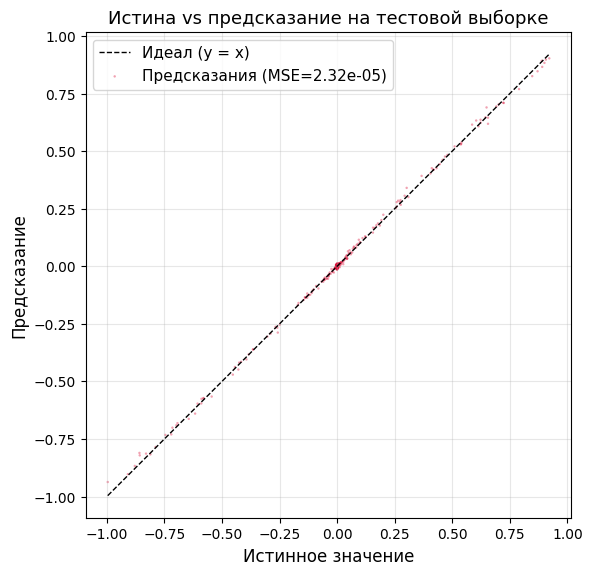

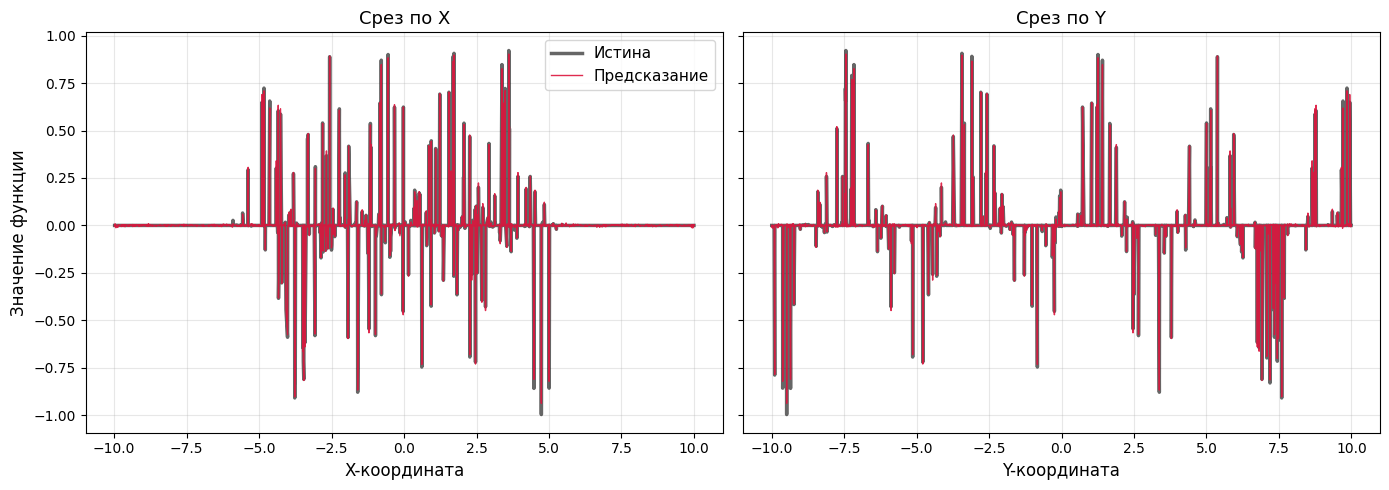

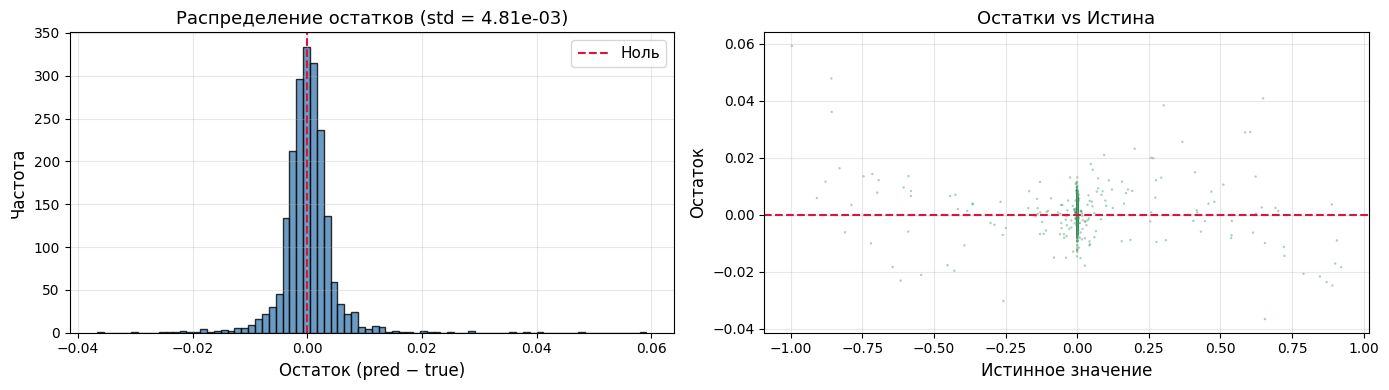

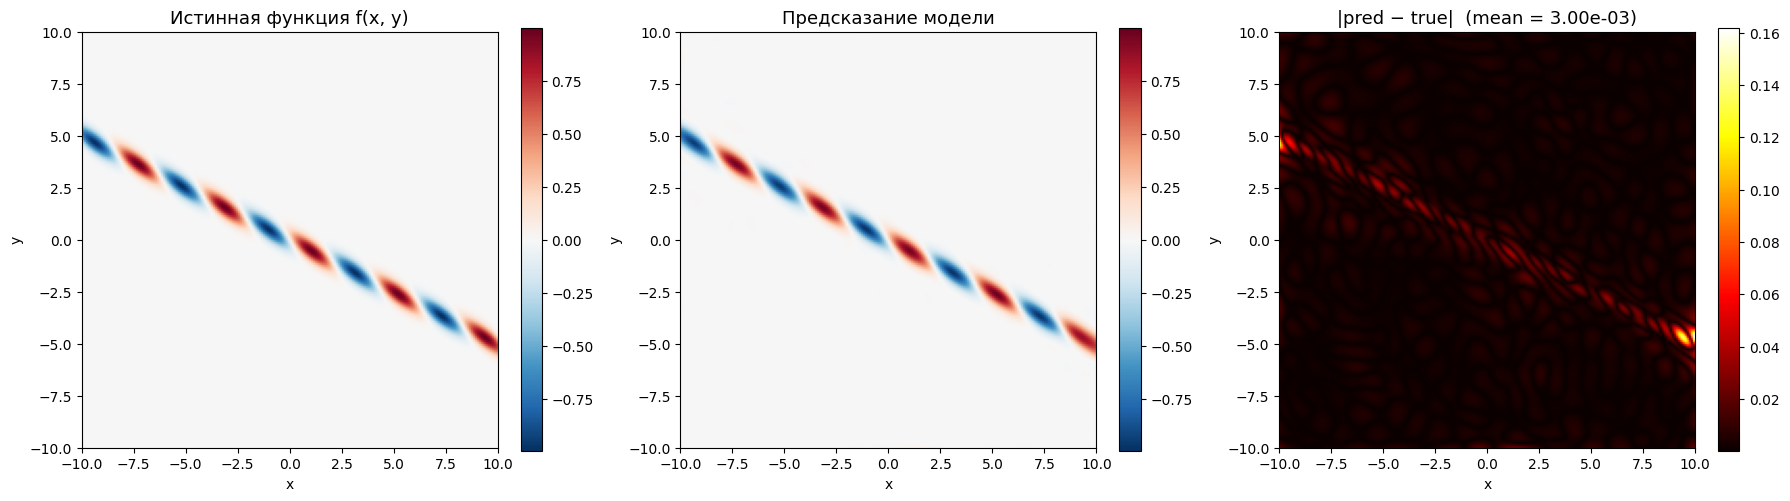

In [ ]:
# Инициализируем модель, отправляем ее в память device
model = SineNet()
model = model.to(device)
# В качестве оптимизатора выбираем Adam
optimizer = torch.optim.Adam(model.parameters(), lr=model.lr)
# Выбрали функцию потерь
loss_fn = nn.MSELoss()

print("Параметров модели:", sum(p.numel() for p in model.parameters()))

# ============================================================
# 5. Обучение (без батча, полный датасет за раз), потенциальную проблему шума для Adamа решим через итерации по эпохам
# ============================================================
def split_xy_target(subset):
    idx = subset.indices
    return xy[idx], target[idx]
xy_train, t_train = split_xy_target(train_ds)
xy_valid, t_valid = split_xy_target(valid_ds)
xy_test, t_test = split_xy_target(test_ds)

epochs = 200
for epoch in range(epochs):
    # Цикл обучения
    model.train()
    # Обнулить накопленные градиент
    optimizer.zero_grad()
    # посчитать pred
    pred = model(xy_train)
    # расчет функции потерь
    loss = loss_fn(pred, t_train)
    loss.backward()
    optimizer.step()
    #  валидация прогресса обучения каждые N эпох ---
    if epoch % 10 == 0:
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(xy_valid), t_valid)
        print(f"Epoch {epoch:4d} | train {loss.item():.3e} | "
              f"val {val_loss.item():.3e}")

# ============================================================
# 6. Проверка на тесте
# ============================================================
model.eval()
with torch.no_grad():
    test_pred = model(xy_test)
    test_loss = loss_fn(test_pred, t_test)

print(f"\nTest MSE: {test_loss.item():.3e}")
print(f"Test RMSE: {math.sqrt(test_loss.item()):.3e}")

# ============================================================
# 7. Построение графиков (оптимизированное)
# ============================================================

Y_true = t_test.detach().cpu().numpy().squeeze()
Y_pred = test_pred.detach().cpu().numpy().squeeze()
X_test = xy_test.detach().cpu().numpy()

# ------------------------------------------------------------
# График 1: Scatter y_true vs y_pred (главный график качества)
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 6))

# Диагональ идеального предсказания
lims = [Y_true.min(), Y_true.max()]
ax.plot(lims, lims, 'k--', linewidth=1, label='Идеал (y = x)')

# Scatter: alpha для прозрачности, s для размера маркера
ax.scatter(Y_true, Y_pred, s=3, alpha=0.4, color='crimson', edgecolors='none',
           label=f'Предсказания (MSE={test_loss.item():.2e})')

ax.set_xlabel('Истинное значение', fontsize=12)
ax.set_ylabel('Предсказание', fontsize=12)
ax.set_title('Истина vs предсказание на тестовой выборке', fontsize=13)
ax.set_aspect('equal', adjustable='box')  # равные масштабы по осям
ax.grid(True, alpha=0.3)
ax.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# График 2: две панели — срез по X и по Y
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, coord, name in zip(axes, [0, 1], ['X', 'Y']):
    # Сортируем по выбранной координате, чтобы получить непрерывные кривые
    order = np.argsort(X_test[:, coord])
    x_sorted = X_test[order, coord]
    y_true_sorted = Y_true[order]
    y_pred_sorted = Y_pred[order]

    # Истина — чёрная жирная кривая снизу
    ax.plot(x_sorted, y_true_sorted, '-', color='black',
            linewidth=2.5, alpha=0.6, label='Истина')
    # Предсказание — красная тонкая линия сверху
    ax.plot(x_sorted, y_pred_sorted, '-', color='crimson',
            linewidth=1.0, alpha=0.9, label='Предсказание')

    ax.set_xlabel(f'{name}-координата', fontsize=12)
    ax.set_title(f'Срез по {name}', fontsize=13)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Значение функции', fontsize=12)
axes[0].legend(loc='best', fontsize=11)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# График 3: гистограмма остатков (ошибок)
# ------------------------------------------------------------
residuals = Y_pred - Y_true

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Гистограмма остатков
axes[0].hist(residuals, bins=80, color='steelblue', edgecolor='black', alpha=0.8)
axes[0].axvline(0, color='crimson', linestyle='--', linewidth=1.5, label='Ноль')
axes[0].set_xlabel('Остаток (pred − true)', fontsize=12)
axes[0].set_ylabel('Частота', fontsize=12)
axes[0].set_title(f'Распределение остатков (std = {residuals.std():.2e})', fontsize=13)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=11)

# Остатки vs истинное значение — проверка на гетероскедастичность
axes[1].scatter(Y_true, residuals, s=3, alpha=0.4, color='seagreen', edgecolors='none')
axes[1].axhline(0, color='crimson', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Истинное значение', fontsize=12)
axes[1].set_ylabel('Остаток', fontsize=12)
axes[1].set_title('Остатки vs Истина', fontsize=13)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 8. 2D-карта ошибки |pred − true| на сетке [-10, 10]²
# ============================================================

# Разрешение сетки. 200x200 = 40000 точек — быстро и достаточно детально
GRID_N = 200

# Создаём сетку
lin = torch.linspace(-10.0, 10.0, GRID_N, device=device)
gx, gy = torch.meshgrid(lin, lin, indexing='ij')       # (GRID_N, GRID_N)
grid_xy = torch.stack([gx.reshape(-1), gy.reshape(-1)], dim=1)   # (N², 2)

# Считаем истину и предсказание на всей сетке
with torch.no_grad():
    grid_true = func(grid_xy[:, 0], grid_xy[:, 1]).reshape(GRID_N, GRID_N)
    grid_pred = model(grid_xy).reshape(GRID_N, GRID_N)
    grid_err  = (grid_pred - grid_true).abs()

# Переносим на CPU для matplotlib
grid_true_np = grid_true.cpu().numpy()
grid_pred_np = grid_pred.cpu().numpy()
grid_err_np  = grid_err.cpu().numpy()
gx_np = gx.cpu().numpy()
gy_np = gy.cpu().numpy()

# ------------------------------------------------------------
# Рисуем 4 панели: истина, предсказание, ошибка, и |ошибка| в лог-шкале
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Общий цветовой диапазон для истины и предсказания (чтобы сравнение было честным)
vmin = min(grid_true_np.min(), grid_pred_np.min())
vmax = max(grid_true_np.max(), grid_pred_np.max())
extent = [-10, 10, -10, 10]

# Панель 1: истинная функция
im1 = axes[0].imshow(grid_true_np, origin='lower', extent=extent,
                     cmap='RdBu_r', vmin=vmin, vmax=vmax, aspect='equal')
axes[0].set_title('Истинная функция f(x, y)', fontsize=13)
axes[0].set_xlabel('x'); axes[0].set_ylabel('y')
plt.colorbar(im1, ax=axes[0], fraction=0.046)

# Панель 2: предсказание модели
im2 = axes[1].imshow(grid_pred_np, origin='lower', extent=extent,
                     cmap='RdBu_r', vmin=vmin, vmax=vmax, aspect='equal')
axes[1].set_title('Предсказание модели', fontsize=13)
axes[1].set_xlabel('x'); axes[1].set_ylabel('y')
plt.colorbar(im2, ax=axes[1], fraction=0.046)

# Панель 3: |ошибка| — самый важный график
im3 = axes[2].imshow(grid_err_np, origin='lower', extent=extent,
                     cmap='hot', aspect='equal')
axes[2].set_title(f'|pred − true|  (mean = {grid_err_np.mean():.2e})', fontsize=13)
axes[2].set_xlabel('x'); axes[2].set_ylabel('y')
plt.colorbar(im3, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

# Пара примеров
#with torch.no_grad():
#    pred5 = model(xy_test[:50])
#print("\nПримеры:")
#for i in range(50):
#    print(f"  f({xy_test[i,0]:+.2f}, {xy_test[i,1]:+.2f}) = "
#          f"{t_test[i,0].item():+.5f} | pred = {pred5[i,0].item():+.5f}")

In [181]:
# Подчистим память для следующего запуска и освободим cuda:
device = 'cpu'

model.to(device)
xy.to(device)
target.to(device)
del model,xy,target, train_ds, valid_ds, test_ds, xy_train, t_train, pred, loss,
gc.collect()
torch.cuda.empty_cache()